## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Santiago Camacho Jimenez" # @param {"type":"string"}
carnet = 1000116319 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**


Una empresa debe administrar tareas tecnicas segun su prioridad y conectar varios dispositivos utilizando la menor cantidad total de cable.

## 2) Requerimientos **[2 pts]**




Requerimientos Funcionales
- Gestionar tareas tecnicas con codigo
- Construir max-heap a partir de una lista inicial de tareas
- Procesar las dos tareas con mayor prioridad
- Poner nuevas tareas manteniendo la estructura max-heap
- Registrar dispositivos con ID
- Generar graficas con la posicion de cada dispositivo

Requerimientos No Funcionales
- No usar heapq
- El MTS debe tener exactamente 5 conexiones
- No se permite usar funciones de librerias que calculen directamente el MST

## 3) Historias de usuario **[2 pts]**


REVISAR

Historia de usuario 1
 - Como tecnico de soporte, quiero organizar las tareas por prioridad en un max-heap, para resolver lo mas urgente de primeras
   - Criterios de aceptacion
      - Al tener el listado de las 6 tareas construir el max-heap
Historia de usuario 2
 - Como coordinador, quiero tener las tareas de mayor prioridad, para ir viendo como queda la cola
   - Criterios de aceptacion
      - Al ejecutar el extract-max primero sale el T02 que tiene prioridad 10, luego el T04 que tiene prioridad 8 y asi sucesivamente
Historia de usuario 3
 - Como supervisor, quiero agregar una tarea urgente por ejemplo T07 conb prioridad 12
   - Criterios de aceptacion
     - Al insertar la tarea T07
     
Historia de usuario 4
 - Como instalador, quiero conectar los 6 dispositivos gastando el menor cable posible, para asi poder reducir los costos
   - Criterios de aceptacion
     - Usando Kruskal ordena las aristas y a partir de la distancia entre los dispositivos muestra la longitud que se necesita de cable


## 4) Diagramas de flujo **[5 pts]**
Incluye el diagrama que muestre el proceso general

Adjunta imagen y descríbelo claramente.


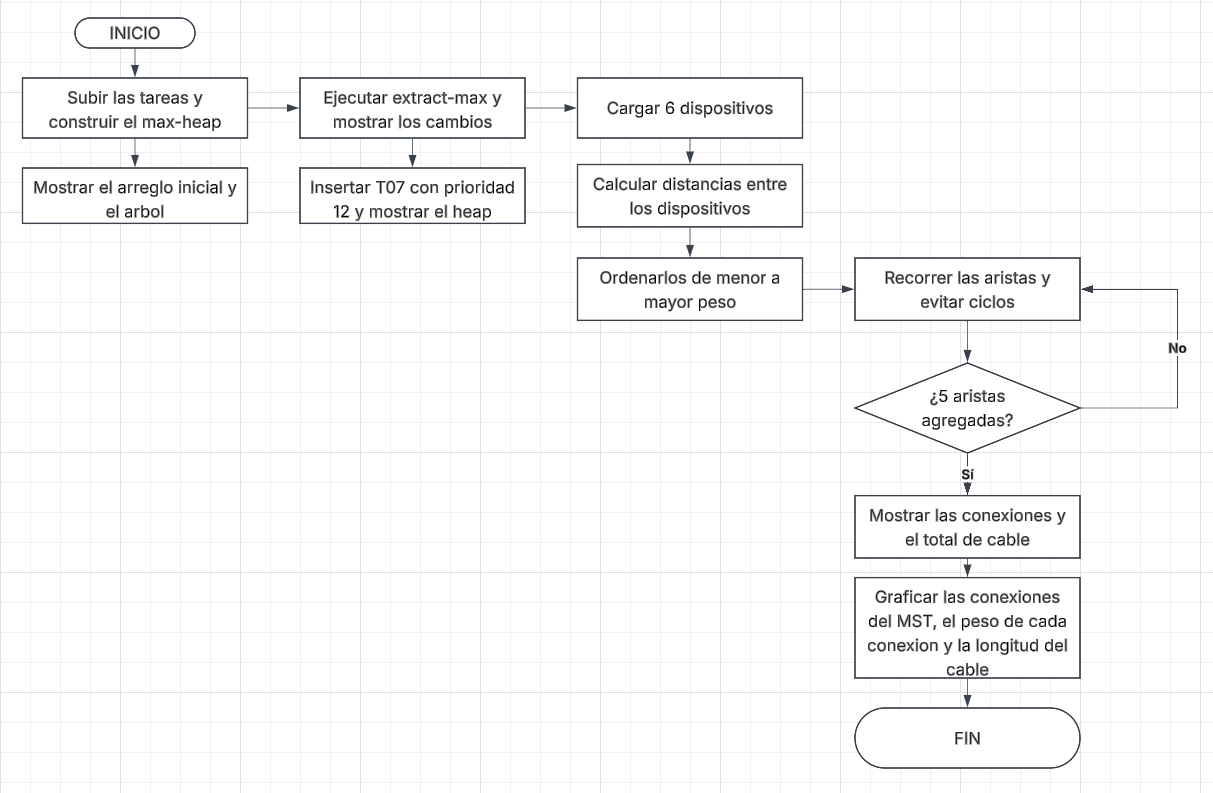

El diagrama nos muestra el paso a paso a seguir, primero suben las tareas, arma el max-heap y muestra su estado inicial y el arbol. Luego hace las extracciones necesarias con extract-max, inserta la tarea T07 con prioridad 12 y actualiza el heap. Despues carga los 6 dispositivos, calcula las distancias entre los dispositivos y ordena los pesos de menor a mayor. Finalmente recorre las aristas evitando que se generen ciclos hasta completar las 5 aristas, muestra las conexiones, el total de cable y hace la grafica final.

### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
   - En el peor caso con max-heapify baja un nodo desde la raiz hasta una hoja haciendo las coparaciones nivel por nivel
   - Con extract-max se mueve el ultimo elemento a la posicion 0 y usa max-heapify
   - Con insert-heap se agrega el elemento al final y lo va intercambiando segun la prioridad. En el peor caso subiria hasta la raiz

- Función T[n]
  - Con max-heapify, extract-max e insert-heap seria T(n)= c1 log2(n) + c2

- Mejor y peor caso con gráfica
  - Verde = Peor caso
  -  Azul = mejor caso


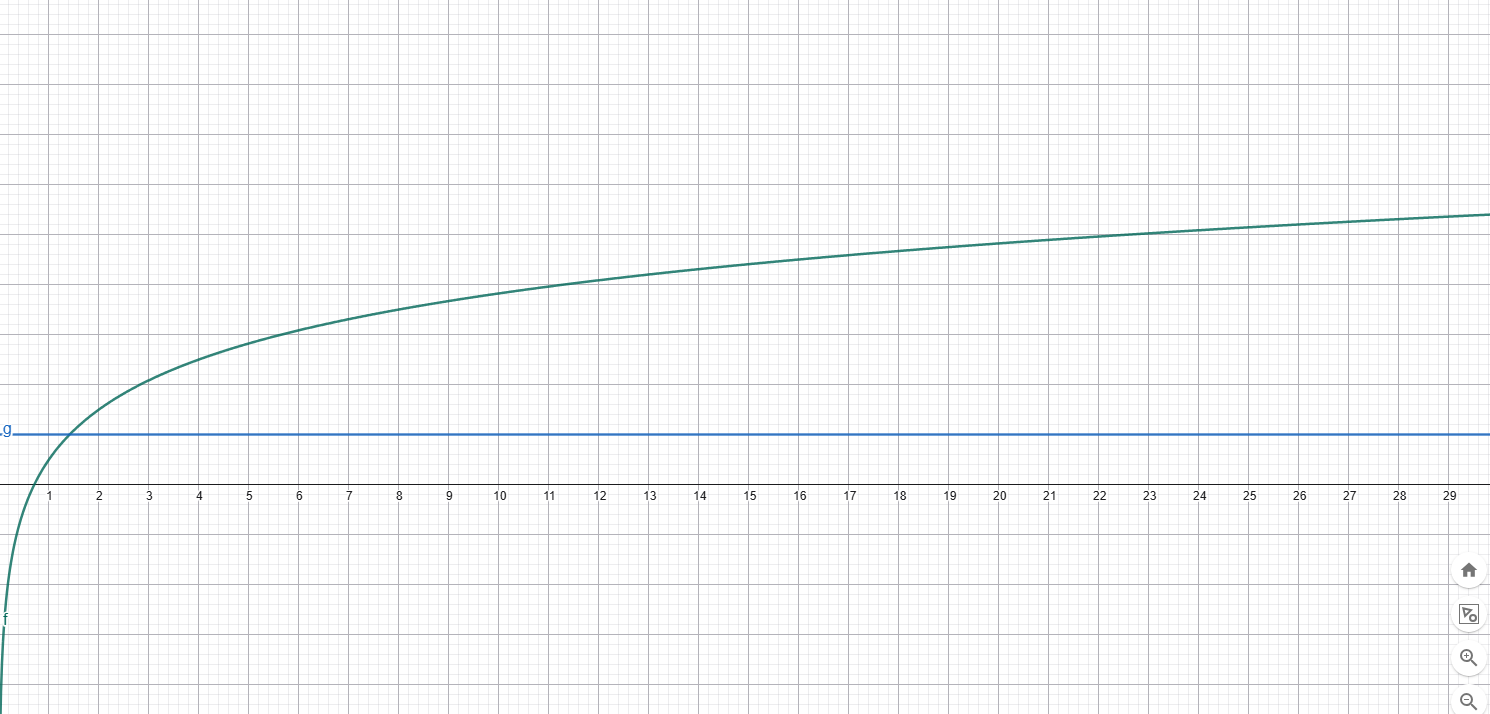

## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [2]:
import math
tareas = [
   {"codigo": "T01", "tarea": "Configurar servidor", "prioridad": 6},
   {"codigo": "T02", "tarea": "Reparar sensor", "prioridad": 10},
   {"codigo": "T03", "tarea": "Actualizar software", "prioridad": 4},
   {"codigo": "T04", "tarea": "Revisar cámara", "prioridad": 8},
   {"codigo": "T05", "tarea": "Generar respaldo", "prioridad": 3},
   {"codigo": "T06", "tarea": "Configurar alarma", "prioridad": 7},
]
def x1(arr, n, i):
   mayor = i
   izq = 2 * i + 1
   der = 2 * i + 2
   if izq < n and arr[izq]["prioridad"] > arr[mayor]["prioridad"]:
       mayor = izq
   if der < n and arr[der]["prioridad"] > arr[mayor]["prioridad"]:
       mayor = der
   if mayor != i:
       arr[i], arr[mayor] = arr[mayor], arr[i]
       x1(arr, n, mayor)
def x2(arr):
   n = len(arr)
   for i in range(n // 2 - 1, -1, -1):
       x1(arr, n, i)
def x3(arr):
   for t in arr:
       print(t["codigo"], t["tarea"], t["prioridad"])
def x4(arr, i=0, niv=0):
   if i < len(arr):
       x4(arr, 2 * i + 2, niv + 1)
       print("  " * niv + f"{arr[i]['codigo']}({arr[i]['prioridad']})")
       x4(arr, 2 * i + 1, niv + 1)
def x5(arr):
   if not arr:
       return None
   top = arr[0]
   ultimo = arr.pop()
   if arr:
       arr[0] = ultimo
       x1(arr, len(arr), 0)
   return top
def x6(arr, nueva):
   arr.append(nueva)
   i = len(arr) - 1
   while i > 0:
       p = (i - 1) // 2
       if arr[i]["prioridad"] > arr[p]["prioridad"]:
           arr[i], arr[p] = arr[p], arr[i]
           i = p
       else:
           break
def x7(x):
   while padre[x] != x:
       padre[x] = padre[padre[x]]
       x = padre[x]
   return x
def x8(u, v):
   ru = x7(u)
   rv = x7(v)
   if ru != rv:
       padre[rv] = ru
       return True
   return False
print("Inicial:")
x3(tareas)
heap = [dict(t) for t in tareas]
x2(heap)
print("\nHeap:")
x3(heap)
print("\nArbol:")
x4(heap)
for k in range(2):
   sale = x5(heap)
   print(f"\nExtraccion {k + 1}: {sale['codigo']} ({sale['prioridad']})")
   x3(heap)
x6(heap, {"codigo": "T07", "tarea": "Falla en sistema contra incendios", "prioridad": 12})
print("\nCon T07:")
x3(heap)
dispositivos = {
   "A": ("Servidor", 2, 2),
   "B": ("Cámara", 7, 3),
   "C": ("Sensor", 4, 7),
   "D": ("Alarma", 10, 8),
   "E": ("Router", 13, 3),
   "F": ("Panel", 15, 7),
}
print("\nPosiciones:")
for k, v in dispositivos.items():
   print(f"{k} ({v[0]}): ({v[1]}, {v[2]})")
nodos = list(dispositivos.keys())
aristas = []
for i in range(len(nodos)):
   for j in range(i + 1, len(nodos)):
       u = nodos[i]
       v = nodos[j]
       _, x1_p, y1_p = dispositivos[u]
       _, x2_p, y2_p = dispositivos[v]
       d = math.sqrt((x2_p - x1_p) ** 2 + (y2_p - y1_p) ** 2)
       aristas.append((d, u, v))
aristas.sort(key=lambda item: item[0])
padre = {n: n for n in nodos}
mst = []
total = 0.0
for peso, u, v in aristas:
   if x8(u, v):
       mst.append((u, v, peso))
       total += peso
       if len(mst) == len(nodos) - 1:
           break
print("\nMST:")
for u, v, peso in mst:
   print(f"{u} - {v}: {peso:2f}")
print(f"Total cable: {total:2f}")

Inicial:
T01 Configurar servidor 6
T02 Reparar sensor 10
T03 Actualizar software 4
T04 Revisar cámara 8
T05 Generar respaldo 3
T06 Configurar alarma 7

Heap:
T02 Reparar sensor 10
T04 Revisar cámara 8
T06 Configurar alarma 7
T01 Configurar servidor 6
T05 Generar respaldo 3
T03 Actualizar software 4

Arbol:
  T06(7)
    T03(4)
T02(10)
    T05(3)
  T04(8)
    T01(6)

Extraccion 1: T02 (10)
T04 Revisar cámara 8
T01 Configurar servidor 6
T06 Configurar alarma 7
T03 Actualizar software 4
T05 Generar respaldo 3

Extraccion 2: T04 (8)
T06 Configurar alarma 7
T01 Configurar servidor 6
T05 Generar respaldo 3
T03 Actualizar software 4

Con T07:
T07 Falla en sistema contra incendios 12
T06 Configurar alarma 7
T05 Generar respaldo 3
T03 Actualizar software 4
T01 Configurar servidor 6

Posiciones:
A (Servidor): (2, 2)
B (Cámara): (7, 3)
C (Sensor): (4, 7)
D (Alarma): (10, 8)
E (Router): (13, 3)
F (Panel): (15, 7)

MST:
E - F: 4.472136
B - C: 5.000000
A - B: 5.099020
D - F: 5.099020
B - D: 5.830952


## 7) Tests aplicados **[15 pts]**

In [ ]:
# (Opcional) Ejemplo de asserts (ajusta a tu código):
# assert funcion(0) == 0
# assert funcion(1) == 1
# assert funcion(6) == 8
